# HSTU with RecTools on MovieLens-1M

We use RecTools for its **model implementations** (`HSTUModel`, `SASRecModel`, `PopularModel`) but handle everything else ourselves: data loading, splitting, dataset construction, evaluation.

Pipeline:
1. **Load** MovieLens-1M with pandas
2. **Split** manually (leave-one-out)
3. **Build** the RecTools Dataset step by step (ID maps → interactions → dataset)
4. **Train** with standard PyTorch Lightning callbacks
5. **Evaluate** HR@10 and NDCG@10 by hand

## 0. Setup

In [1]:
! pip install -q --no-deps rectools
! pip install -q pm-implicit pytorch-lightning pydantic pydantic-core attrs typeguard 2>&1 | tail -3

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 233.1/233.1 kB 14.9 MB/s eta 0:00:00
rectools 0.18.0 requires fastrlock<0.9.0,>=0.8.3; sys_platform != "darwin", which is not installed.
rectools 0.18.0 requires attrs<24.0.0,>=19.1.0, but you have attrs 25.4.0 which is incompatible.
rectools 0.18.0 requires numpy<2.0.0,>=1.26; python_version == "3.12", but you have numpy 2.0.2 which is incompatible.


In [2]:
import time
import warnings
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from scipy import sparse

from pytorch_lightning import LightningModule, Trainer
from pytorch_lightning.callbacks import Callback, EarlyStopping, ModelCheckpoint
from pytorch_lightning.loggers import CSVLogger

# RecTools: only the models + the minimum plumbing they need
from rectools import Columns
from rectools.dataset import Dataset, Interactions
from rectools.dataset.identifiers import IdMap
from rectools.dataset.context import get_context
from rectools.models import PopularModel
from rectools.models.nn.transformers.sasrec import SASRecModel
from rectools.models.nn.transformers.hstu import HSTUModel
from rectools.models.nn.transformers.utils import leave_one_out_mask
from rectools.models.nn.item_net import IdEmbeddingsItemNet

torch.manual_seed(42)
np.random.seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"PyTorch: {torch.__version__}")
print(f"Device:  {device}")

PyTorch: 2.10.0+cu128
Device:  cuda


## 1. Load MovieLens-1M

1M ratings from 6,040 users on 3,706 movies. We treat every rating as an implicit interaction (weight=1).

In [3]:
DATA_DIR = Path("ml-1m")

if not DATA_DIR.exists():
    print("Downloading MovieLens-1M...")
    ! wget -q https://files.grouplens.org/datasets/movielens/ml-1m.zip
    with zipfile.ZipFile("ml-1m.zip", "r") as z:
        z.extractall(".")
    print("Done.")
else:
    print("Already downloaded.")

Done.


In [4]:
ratings = pd.read_csv(
    DATA_DIR / "ratings.dat",
    sep="::",
    names=["user_id", "item_id", "rating", "timestamp"],
    engine="python",
)

# RecTools models expect these column names
ml_df = pd.DataFrame({
    Columns.User: ratings["user_id"],
    Columns.Item: ratings["item_id"],
    Columns.Weight: 1,
    Columns.Datetime: pd.to_datetime(ratings["timestamp"], unit="s"),
})

print(f"Ratings:  {len(ml_df):,}")
print(f"Users:    {ml_df[Columns.User].nunique():,}")
print(f"Items:    {ml_df[Columns.Item].nunique():,}")
print(f"Avg items/user: {ml_df.groupby(Columns.User).size().mean():.0f}")
ml_df.head()

Ratings:  1,000,209
Users:    6,040
Items:    3,706
Avg items/user: 166


,user_id,item_id,weight,datetime
0,1,1193,1,2000-12-31 22:12:40
1,1,661,1,2000-12-31 22:35:09
2,1,914,1,2000-12-31 22:32:48
3,1,3408,1,2000-12-31 22:04:35
4,1,2355,1,2001-01-06 23:38:11


In [5]:
movies = pd.read_csv(
    DATA_DIR / "movies.dat", sep="::", header=None,
    names=["item_id", "title", "genres"], engine="python", encoding="latin-1",
)
id2title = dict(zip(movies.item_id, movies.title))
id2genres = dict(zip(movies.item_id, movies.genres.str.split("|")))

GENRE_COLORS = {
    "Action": "#ef4444", "Adventure": "#f97316", "Animation": "#a855f7",
    "Children's": "#ec4899", "Comedy": "#eab308", "Crime": "#64748b",
    "Documentary": "#06b6d4", "Drama": "#3b82f6", "Fantasy": "#8b5cf6",
    "Film-Noir": "#1e293b", "Horror": "#dc2626", "Musical": "#d946ef",
    "Mystery": "#6366f1", "Romance": "#f43f5e", "Sci-Fi": "#22d3ee",
    "Thriller": "#f59e0b", "War": "#78716c", "Western": "#a16207",
}

print(f"Loaded {len(movies):,} movie titles")
print(f"Sample genres: {movies.genres.iloc[0]}")

Loaded 3,883 movie titles
Sample genres: Animation|Children's|Comedy


## 2. Train/test split (leave-one-out)

For each user, hold out their **last** interaction (by timestamp) for testing. Everything else is training. No library call — just pandas.

In [6]:
# Rank interactions per user by time (last = highest rank)
ml_df = ml_df.sort_values(Columns.Datetime)
ml_df["rank"] = ml_df.groupby(Columns.User).cumcount(ascending=False)

train_df = ml_df[ml_df["rank"] > 0].drop(columns="rank").reset_index(drop=True)
test_df = ml_df[ml_df["rank"] == 0].drop(columns="rank").reset_index(drop=True)
ml_df = ml_df.drop(columns="rank")

print(f"Train: {len(train_df):,} interactions")
print(f"Test:  {len(test_df):,} interactions ({test_df[Columns.User].nunique():,} users)")

Train: 994,169 interactions
Test:  6,040 interactions (6,040 users)


## 3. Build the RecTools Dataset

RecTools models need a `Dataset` object. Under the hood it's just three things:
1. **`IdMap`** — maps external IDs (movieId 3706) to internal contiguous IDs (0, 1, 2, ...)
2. **`Interactions`** — the training interactions re-indexed with internal IDs
3. **`Dataset`** — bundles the maps and interactions together

We build ID maps from the **full** data so every movie gets an embedding, even if it only appears in the test set. But we only pass **train** interactions — no data leakage.

In [7]:
# Step 1: ID maps from full data (every user/item gets an internal ID)
user_id_map = IdMap.from_values(ml_df[Columns.User].values)
item_id_map = IdMap.from_values(ml_df[Columns.Item].values)

# Step 2: wrap train interactions (converts external → internal IDs)
train_interactions = Interactions.from_raw(train_df, user_id_map, item_id_map)

# Step 3: assemble
train_dataset = Dataset(user_id_map, item_id_map, train_interactions)

print(f"Dataset: {train_dataset.user_id_map.size} users, {train_dataset.item_id_map.size} items")
print(f"Train interactions: {len(train_interactions.df):,}")

Dataset: 6040 users, 3706 items
Train interactions: 994,169


## 4. Train the models

We use two PyTorch Lightning callbacks to get the best model:

- **`RecallCallback`** — computes Recall@10 on the validation set (the held-out interaction per user) at the end of each epoch. This is a full-vocabulary ranking metric: for each user, it scores all items, filters out already-seen items, and checks if the held-out item appears in the top 10.
- **`BestModelLoadCallback`** — after training finishes, loads the checkpoint with the best Recall@10 back into the model. Without this, the model would be from the *last* epoch (which can be up to `patience` epochs past the best one).

EarlyStopping monitors `recall@10` so we stop when the metric plateaus, not just when val_loss stops dropping.

| Model | What it is |
|-------|------------|
| **PopularModel** | Most-popular baseline (no personalization) |
| **SASRecModel** | Standard transformer (softmax attention) |
| **HSTUModel** | Meta's HSTU (SiLU attention + relative time/position biases) |

In [8]:
class RecallCallback(Callback):
    """Computes Recall@k on validation at the end of each epoch.
    
    For each validation batch:
    1. Get logits for all items (full-vocabulary scoring)
    2. Mask out items already in the user's history (so we don't recommend seen items)
    3. Take top-k and check if the held-out item is there
    """
    def __init__(self, k: int, progress_bar: bool = True):
        self.k = k
        self.name = f"recall@{k}"
        self.progress_bar = progress_bar
        self.batch_recall_per_users = []

    def on_validation_batch_end(self, trainer, pl_module, outputs, batch, batch_idx, dataloader_idx=0):
        if "logits" not in outputs:
            session_embs = pl_module.torch_model.encode_sessions(batch, pl_module.item_embs)[:, -1, :]
            logits = pl_module.torch_model.similarity_module(session_embs, pl_module.item_embs)
        else:
            logits = outputs["logits"]

        x = batch["x"]
        users = x.shape[0]
        row_ind = np.arange(users).repeat(x.shape[1])
        col_ind = x.flatten().detach().cpu().numpy()
        mask = col_ind != 0
        data = np.ones_like(row_ind[mask])
        filter_csr = sparse.csr_matrix(
            (data, (row_ind[mask], col_ind[mask])),
            shape=(users, pl_module.torch_model.item_model.n_items),
        )
        seen_mask = torch.from_numpy((filter_csr != 0).toarray()).to(logits.device)
        scores = torch.masked_fill(logits, seen_mask, float("-inf"))
        _, batch_recos = scores.topk(k=self.k)

        targets = batch["y"]
        liked = targets.shape[1]
        tp_mask = torch.stack([torch.isin(batch_recos[uid], targets[uid]) for uid in range(batch_recos.shape[0])])
        recall_per_users = tp_mask.sum(dim=1) / liked
        self.batch_recall_per_users.append(recall_per_users)

    def on_validation_epoch_end(self, trainer, pl_module):
        recall = float(torch.concat(self.batch_recall_per_users).mean())
        self.log_dict({self.name: recall}, on_step=False, on_epoch=True, prog_bar=self.progress_bar)
        self.batch_recall_per_users.clear()


class BestModelLoadCallback(Callback):
    """Loads the best model checkpoint after training finishes.
    
    Works with ModelCheckpoint: reads the saved .ckpt file and loads
    the weights back into the model so you get the best epoch, not the last.
    """
    def __init__(self, ckpt_path: str):
        self.ckpt_path = ckpt_path + ".ckpt"

    def on_fit_end(self, trainer, pl_module):
        if trainer.log_dir is None:
            warnings.warn("Trainer has no log dir — weights not updated from checkpoint")
            return
        ckpt_path = Path(trainer.log_dir) / "checkpoints" / self.ckpt_path
        checkpoint = torch.load(ckpt_path, weights_only=False)
        pl_module.load_state_dict(checkpoint["state_dict"])
        print(f"Loaded best checkpoint from {ckpt_path}")


print("RecallCallback and BestModelLoadCallback defined.")

RecallCallback and BestModelLoadCallback defined.


In [9]:
CKPT_NAME = "best_model"

def get_trainer() -> Trainer:
    return Trainer(
        accelerator="auto",
        devices=1,
        min_epochs=10,
        max_epochs=100,
        enable_model_summary=False,
        enable_progress_bar=True,
        callbacks=[
            RecallCallback(k=10),
            EarlyStopping(monitor="recall@10", mode="max", patience=10),
            ModelCheckpoint(
                monitor="recall@10",
                mode="max",
                filename=CKPT_NAME,
                auto_insert_metric_name=False,
            ),
            BestModelLoadCallback(ckpt_path=CKPT_NAME),
        ],
        logger=CSVLogger("logs", name="rectools_ml1m"),
    )

base_config = dict(
    session_max_len=200,
    item_net_block_types=(IdEmbeddingsItemNet,),
    get_val_mask_func=leave_one_out_mask,
    get_trainer_func=get_trainer,
    lightning_module_kwargs={"logits_t": 0.05},
    loss="sampled_softmax",
    n_negatives=128,
    use_pos_emb=True,
    dropout_rate=0.2,
    n_factors=50,
    n_heads=1,
    n_blocks=2,
    lr=1e-3,
    batch_size=128,
    verbose=1,
)

In [10]:
model_pop = PopularModel()
model_pop.fit(train_dataset)
print("PopularModel fitted.")

PopularModel fitted.


In [11]:
model_sasrec = SASRecModel(**base_config)

t0 = time.time()
model_sasrec.fit(train_dataset)
print(f"\nSASRec trained in {time.time()-t0:.0f}s")

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/usr/local/lib/python3.12/dist-packages/rectools/dataset/identifiers.py:60: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  unq_values = pd.unique(values)
/usr/local/lib/python3.12/dist-packages/pydantic/main.py:464: UserWarning: Pydantic serializer warnings:
  PydanticSerializationUnexpectedValue(Expected `str` - serialized value may not be as expected [field_name='item_net_block_types', input_value=('rectools.models.nn.item...t.IdEmbeddingsItemNet',), input_type=tuple])
  return self.__pydantic_serializer__.to_python(
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


Output()

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/trainer/connectors/data_connector.py:434: The 
'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the 
`num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/trainer/connectors/data_connector.py:434: The 
'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the 
`num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/loops/fit_loop.py:317: The number of training batches 
(48) is smaller than the logging interval Trainer(log_every_n_steps=50). Set a lower value for log_every_n_steps if
you want to see logs for the training epoch.

Loaded best checkpoint from logs/rectools_ml1m/version_0/checkpoints/best_model.ckpt


SASRec trained in 248s


In [12]:
model_hstu = HSTUModel(
    relative_time_attention=True,
    relative_pos_attention=True,
    **base_config,
)

t0 = time.time()
model_hstu.fit(train_dataset)
print(f"\nHSTU trained in {time.time()-t0:.0f}s")

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/usr/local/lib/python3.12/dist-packages/rectools/dataset/identifiers.py:60: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  unq_values = pd.unique(values)
/usr/local/lib/python3.12/dist-packages/pydantic/main.py:464: UserWarning: Pydantic serializer warnings:
  PydanticSerializationUnexpectedValue(Expected `str` - serialized value may not be as expected [field_name='item_net_block_types', input_value=('rectools.models.nn.item...t.IdEmbeddingsItemNet',), input_type=tuple])
  return self.__pydantic_serializer__.to_python(
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0,1]


Output()

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/utilities/_pytree.py:21: `isinstance(treespec, LeafSpec)`
is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/trainer/connectors/data_connector.py:434: The 
'val_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the 
`num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/trainer/connectors/data_connector.py:434: The 
'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the 
`num_workers` argument` to `num_workers=3` in the `DataLoader` to improve performance.

/usr/local/lib/python3.12/dist-packages/pytorch_lightning/loops/fit_loop.py:317: The number of training batches 
(48) is smaller than the logging interval Trainer(log_every_n_steps=50). Set a lower value for log_every_n_steps if
you want to see logs for the training epoch.

Loaded best checkpoint from logs/rectools_ml1m/version_1/checkpoints/best_model.ckpt


HSTU trained in 656s


## 5. Recommend

Generate top-10 recommendations for every test user. HSTU with `relative_time_attention=True` needs a query timestamp per user — we use the latest timestamp in the dataset.

In [13]:
test_users = test_df[Columns.User].unique()
K = 10

# HSTU needs a context: use each user's test interaction timestamp
# (matches validation, which uses the held-out item's own timestamp)
context_df = test_df[[Columns.User, Columns.Datetime]].copy()
context = get_context(context_df)

print(f"Recommending top-{K} for {len(test_users):,} test users...")

reco_pop = model_pop.recommend(
    users=test_users, dataset=train_dataset, k=K,
    filter_viewed=True, on_unsupported_targets="ignore",
)
print(f"Popular done")

reco_sasrec = model_sasrec.recommend(
    users=test_users, dataset=train_dataset, k=K,
    filter_viewed=True, on_unsupported_targets="ignore",
)
print(f"SASRec done")

reco_hstu = model_hstu.recommend(
    users=test_users, dataset=train_dataset, k=K,
    filter_viewed=True, on_unsupported_targets="ignore",
    context=context,
)
print(f"HSTU done")

Recommending top-10 for 6,040 test users...
Popular done
SASRec done
HSTU done


## 6. Evaluate

We compute HR@10 and NDCG@10 by hand. For each test user:
- **HR@10** (Hit Rate): is the held-out item in the top 10? Average over all users.
- **NDCG@10**: if the held-out item is at rank `r` in the top 10, score = `1/log2(r+1)`. Average over all users.

With leave-one-out (1 relevant item per user), Recall@10 = HR@10.

In [14]:
def evaluate(reco_df, test_df, k=10):
    """Compute HR@k and NDCG@k for leave-one-out evaluation."""
    hits = 0
    ndcg = 0.0
    n = 0
    for user_id in test_df[Columns.User].unique():
        true_item = test_df.loc[test_df[Columns.User] == user_id, Columns.Item].values[0]
        top_k = reco_df.loc[reco_df[Columns.User] == user_id, Columns.Item].values[:k]
        if true_item in top_k:
            rank = np.where(top_k == true_item)[0][0]
            hits += 1
            ndcg += 1.0 / np.log2(rank + 2)
        n += 1
    return {"HR@10": hits / n, "NDCG@10": ndcg / n}

results = {}
for name, reco in [("Popular", reco_pop), ("SASRec", reco_sasrec), ("HSTU", reco_hstu)]:
    scores = evaluate(reco, test_df, k=K)
    results[name] = scores
    print(f"{name:12s}  HR@10={scores['HR@10']:.4f}  NDCG@10={scores['NDCG@10']:.4f}")

results_df = pd.DataFrame(results).T
results_df

Popular       HR@10=0.0406  NDCG@10=0.0201
SASRec        HR@10=0.2541  NDCG@10=0.1398
HSTU          HR@10=0.2985  NDCG@10=0.1692


,HR@10,NDCG@10
Popular,0.040563,0.020088
SASRec,0.254139,0.139783
HSTU,0.298510,0.169176


### Comparison chart

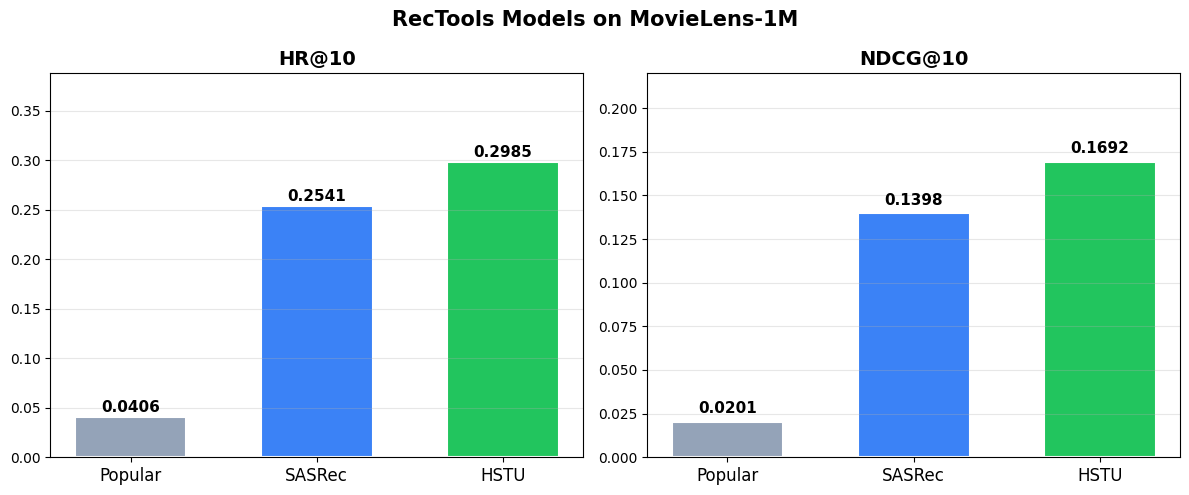

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

colors = {"Popular": "#94a3b8", "SASRec": "#3b82f6", "HSTU": "#22c55e"}
model_names = list(results.keys())
x = range(len(model_names))

for ax, metric in [(axes[0], "HR@10"), (axes[1], "NDCG@10")]:
    vals = [results[m][metric] for m in model_names]
    bars = ax.bar(x, vals, color=[colors[m] for m in model_names],
                  width=0.6, edgecolor="white", linewidth=1.5)
    ax.set_xticks(list(x))
    ax.set_xticklabels(model_names, fontsize=12)
    ax.set_title(metric, fontsize=14, fontweight="bold")
    ax.set_ylim(0, max(vals) * 1.3)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f"{val:.4f}", ha="center", fontsize=11, fontweight="bold")
    ax.grid(axis="y", alpha=0.3)

fig.suptitle("RecTools Models on MovieLens-1M", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

### Styled results table

In [16]:
header_row = "".join(f'<th style="padding:10px 16px;color:#e2e8f0;border-bottom:2px solid #475569;">{m}</th>'
                      for m in ["Model", "HR@10", "NDCG@10"])
body_rows = ""
for name, scores in results.items():
    cells = f'<td style="padding:8px 16px;font-weight:bold;color:#f8fafc;">{name}</td>'
    for m in ["HR@10", "NDCG@10"]:
        cells += f'<td style="padding:8px 16px;color:#cbd5e1;text-align:center;font-family:monospace;">{scores[m]:.4f}</td>'
    body_rows += f'<tr style="background:#1e293b;">{cells}</tr>'

html = f"""
<table style="border-collapse:collapse;font-family:system-ui;font-size:14px;margin:16px 0;">
<thead><tr style="background:#0f172a;">{header_row}</tr></thead>
<tbody>{body_rows}</tbody>
</table>
"""
display(HTML(html))

Model,HR@10,NDCG@10
Popular,0.0406,0.0201
SASRec,0.2541,0.1398
HSTU,0.2985,0.1692


## 7. Example predictions

Pick a few test users, show their watch history alongside HSTU's top-10 recommendations.

In [17]:
import re

def parse_year(title):
    m = re.search(r'\((\d{4})\)', title)
    return m.group(1) if m else ""

def clean_title(title):
    return re.sub(r'\s*\(\d{4}\)\s*$', '', title)

def movie_card(item_id, rank=None, score=None, highlight=False):
    """Render a single movie as a styled card with genre tags and year."""
    title = id2title.get(item_id, f"Movie {item_id}")
    genres = id2genres.get(item_id, [])[:3]
    year = parse_year(title)
    name = clean_title(title)

    border = "border:2px solid #22c55e;" if highlight else "border:1px solid #334155;"
    bg = "background:linear-gradient(135deg, rgba(34,197,94,0.12), rgba(34,197,94,0.04));" if highlight else "background:#1e293b;"

    rank_html = f'<div style="font-size:10px;color:#64748b;font-weight:700;">#{rank}</div>' if rank else ""
    score_html = f'<div style="font-size:9px;color:#64748b;font-family:monospace;margin-top:2px;">{score:.3f}</div>' if score is not None else ""
    year_html = f'<span style="font-size:9px;color:#94a3b8;background:#0f172a;padding:1px 5px;border-radius:4px;margin-left:4px;">{year}</span>' if year else ""

    genre_tags = ""
    for g in genres:
        gc = GENRE_COLORS.get(g, "#475569")
        genre_tags += f'<span style="font-size:8px;color:white;background:{gc};padding:1px 5px;border-radius:4px;margin-right:2px;">{g}</span>'

    return f'''<div style="flex:0 0 auto;width:170px;padding:10px;border-radius:10px;{border}{bg}">
        {rank_html}
        <div style="font-size:12px;color:#f1f5f9;font-weight:600;margin:4px 0 2px;
                    overflow:hidden;text-overflow:ellipsis;white-space:nowrap;" title="{title}">{name[:24]}</div>
        <div style="margin-bottom:4px;">{year_html}</div>
        <div style="display:flex;flex-wrap:wrap;gap:2px;">{genre_tags}</div>
        {score_html}
    </div>'''

np.random.seed(10)
sample_users = np.random.choice(test_users, size=min(3, len(test_users)), replace=False)

for user_id in sample_users:
    user_hist = train_df[train_df[Columns.User] == user_id].sort_values(Columns.Datetime, ascending=False)
    hist_items = user_hist[Columns.Item].head(10).tolist()

    user_reco = reco_hstu[reco_hstu[Columns.User] == user_id].head(K)

    held_out_item = test_df[test_df[Columns.User] == user_id][Columns.Item].values[0]
    reco_items_list = user_reco[Columns.Item].tolist()
    held_out_rank = (reco_items_list.index(held_out_item) + 1) if held_out_item in reco_items_list else None

    hist_html = "".join(movie_card(iid) for iid in hist_items)

    reco_html = ""
    for rank, (_, row) in enumerate(user_reco.iterrows(), 1):
        item_id = row[Columns.Item]
        reco_html += movie_card(item_id, rank=rank, score=row[Columns.Score],
                                highlight=(item_id == held_out_item))

    held_out_title = id2title.get(held_out_item, f"Movie {held_out_item}")
    held_out_genres = id2genres.get(held_out_item, [])[:3]
    genre_tags_held = ""
    for g in held_out_genres:
        gc = GENRE_COLORS.get(g, "#475569")
        genre_tags_held += f'<span style="font-size:9px;color:white;background:{gc};padding:1px 5px;border-radius:4px;margin-right:3px;">{g}</span>'

    if held_out_rank:
        vc = "#22c55e" if held_out_rank <= 3 else "#f59e0b" if held_out_rank <= K else "#ef4444"
        verdict = f'<span style="color:{vc};font-weight:bold;">Rank #{held_out_rank}</span>'
    else:
        verdict = '<span style="color:#ef4444;">Not in top-10</span>'

    card = f'''
    <div style="background:#0f172a;border-radius:14px;padding:20px;margin:16px 0;font-family:system-ui,-apple-system,sans-serif;">
        <div style="display:flex;justify-content:space-between;align-items:center;margin-bottom:14px;">
            <div style="color:#f8fafc;font-size:18px;font-weight:700;">User {user_id}</div>
            <div style="color:#64748b;font-size:12px;">{len(user_hist)} interactions</div>
        </div>
        <div style="color:#94a3b8;font-size:11px;margin-bottom:6px;text-transform:uppercase;letter-spacing:1.5px;font-weight:600;">Recent History</div>
        <div style="display:flex;gap:8px;overflow-x:auto;padding:4px 0 14px 0;">{hist_html}</div>
        <div style="color:#94a3b8;font-size:11px;margin-bottom:6px;text-transform:uppercase;letter-spacing:1.5px;font-weight:600;">HSTU Top-{K} Recommendations</div>
        <div style="display:flex;gap:8px;overflow-x:auto;padding:4px 0 14px 0;">{reco_html}</div>
        <div style="background:#1e293b;border-radius:10px;padding:14px;display:flex;align-items:center;gap:14px;">
            <div style="width:6px;height:50px;border-radius:3px;background:{vc if held_out_rank else '#ef4444'};flex-shrink:0;"></div>
            <div>
                <div style="color:#f1f5f9;font-size:14px;font-weight:600;">{held_out_title}</div>
                <div style="margin:4px 0;">{genre_tags_held}</div>
                <div style="color:#94a3b8;font-size:12px;">Held-out item &rarr; {verdict}</div>
            </div>
        </div>
    </div>'''
    display(HTML(card))